# Continuidad y movimientos del azúcar No. 11

**Serie III.2.** El objetivo es comprobar si los niveles y varios movimientos del archivo `Sugar_data.csv` coinciden con evidencia pública del mismo mercado, identificar saltos que requieren revisión y precisar qué no puede certificarse sin vencimientos diarios. No se construye una serie corregida.

El PDF de la prueba es confidencial y no se reproduce aquí.

## Método y límites

Se conservan las 6,097 filas crudas. Se contrastan las medias de cierres diarios del archivo con la serie mensual USDA ERS Table 3b, descrita por USDA como promedio de liquidaciones diarias ICE No. 11 del vencimiento cercano. Las unidades son centavos de dólar por libra. El mes parcial junio de 2024 se separa del análisis mensual principal.

Como cotejos por vencimiento, se transcriben tablas de mercado contemporáneas del mismo contrato Mar-11. Las cotizaciones del 5, 12 y 19 de noviembre están separadas por siete días calendario; sus cambios describen variación semanal entre referencias, no retornos de una sola sesión. La tabla del 26 de noviembre repite exactamente la del 19 y se marca como posible republicación.

USDA aporta comparación agregada mensual, no observaciones diarias pareadas. Los boletines FNB son cotizaciones secundarias del mercado y la tabla ICE Arb Mark es una indicación intradía no oficial. Ninguna de estas piezas documenta la selección histórica de contratos o ajustes usados por Yahoo/Kaggle.

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import pandas as pd

RAIZ = Path.cwd()
if not (RAIZ / "scripts/verificar_continuidad_serie3.py").exists():
    RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts/verificar_continuidad_serie3.py").exists())
sys.path.insert(0, str(RAIZ))
from scripts.verificar_continuidad_serie3 import ejecutar

resultado = ejecutar(RAIZ)
OUT = RAIZ / "outputs/serie3_continuidad"
crudo = pd.read_csv(RAIZ / "data/raw/serie3/Sugar_data.csv", parse_dates=["date"])
mensual = pd.read_csv(OUT / "contraste_mensual_usda.csv")
fnb = pd.read_csv(OUT / "movimientos_mismo_vencimiento_fnb.csv", parse_dates=["date"])
revision = pd.read_csv(OUT / "revision_extremos_2000_2008.csv", parse_dates=["date"])
print(f"Filas crudas conservadas: {len(crudo):,}")
print(f"Meses completos contrastados: {resultado['usda_meses_completos_contraste']} de 291")
print(f"Mes parcial separado: {resultado['usda_meses_parciales_detalle'][0]['mes']}")

Filas crudas conservadas: 6,097
Meses completos contrastados: 291 de 291
Mes parcial separado: 2024-06


## Coincidencia mensual con USDA ERS

La mediana y el percentil 90 de la diferencia porcentual absoluta se calculan solo con los 291 meses completos. También se muestran todos los meses cuya diferencia supera 1%; esos casos pueden reflejar distintos vencimientos de referencia, reglas de cercanía o problemas de linaje, y no se clasifican como errores probados.

In [2]:
comparables = mensual.loc[mensual.mes_completo_en_archivo].dropna(subset=["usda_cercano_mensual"]).copy()
comparables["diferencia_abs_pct"] = comparables.diferencia_pct.abs()
print(f"Meses completos: {len(comparables)}")
print(f"Mediana de diferencia absoluta: {comparables.diferencia_abs_pct.median():.5f}%")
print(f"P90 de diferencia absoluta: {comparables.diferencia_abs_pct.quantile(.90):.5f}%")
print(f"Meses con diferencia ≤ 0.0011 centavos/libra: {comparables.diferencia_centavos.abs().le(.0011).sum()} / {len(comparables)}")
comparables.loc[comparables.diferencia_abs_pct.gt(1), ["mes", "cierre_medio", "usda_cercano_mensual", "diferencia_centavos", "diferencia_pct"]].round(4)

Meses completos: 291
Mediana de diferencia absoluta: 0.00543%
P90 de diferencia absoluta: 0.14998%
Meses con diferencia ≤ 0.0011 centavos/libra: 158 / 291


,mes,cierre_medio,usda_cercano_mensual,diferencia_centavos,diferencia_pct
31,2002-10,7.0200,7.279,-0.2590,-3.5582
32,2002-11,7.2968,7.518,-0.2212,-2.9417
43,2003-10,6.0983,5.696,0.4023,7.0622
44,2003-11,6.1911,5.574,0.6171,11.0712
45,2003-12,6.3438,4.667,1.6768,35.9291
127,2010-10,26.9438,28.580,-1.6362,-5.7249
136,2011-07,29.4710,30.510,-1.0390,-3.4054
143,2012-02,24.8835,25.810,-0.9265,-3.5897
153,2012-12,19.2020,19.500,-0.2980,-1.5282
154,2013-01,18.7081,18.370,0.3381,1.8405


Junio de 2024 termina el día 24 y no se trata como mes completo. Se conserva su cotejo descriptivo para que la diferencia parcial sea visible.

In [3]:
mensual.loc[~mensual.mes_completo_en_archivo, ["mes", "sesiones", "cierre_medio", "usda_cercano_mensual", "diferencia_centavos", "diferencia_pct"]].round(4)

,mes,sesiones,cierre_medio,usda_cercano_mensual,diferencia_centavos,diferencia_pct
291,2024-06,15,19.0473,19.183,-0.1357,-0.7072


### Una discrepancia de ERS en 2003

En octubre–diciembre de 2003, ERS reporta 5.696, 5.574 y 4.667 centavos/libra. La serie oficial mensual INSEE para el primer vencimiento cercano de ICE Nueva York publica 6.1, 6.2 y 6.3, redondeados a una decimal. Las medias del CSV son 6.098, 6.191 y 6.344. Este contraste puntual indica que la discrepancia no se resuelve declarando que ERS es la verdad exacta: INSEE se aproxima al CSV, mientras ERS queda separado en esos meses. Como INSEE redondea y ambas fuentes no exponen aquí observaciones diarias por contrato, el resultado sugiere revisar la serie ERS o sus definiciones, sin certificar cada día del CSV.

In [4]:
insee = pd.read_csv(OUT / "divergencia_2003_insee.csv")
insee[["mes", "cierre_medio", "usda_cercano_mensual", "insee_cercano", "diferencia_csv_centavos", "diferencia_ers_centavos"]].round(3)

,mes,cierre_medio,usda_cercano_mensual,insee_cercano,diferencia_csv_centavos,diferencia_ers_centavos
0,2003-10,6.098,5.696,6.1,-0.002,-0.404
1,2003-11,6.191,5.574,6.2,-0.009,-0.626
2,2003-12,6.344,4.667,6.3,0.044,-1.633


## Movimientos publicados para el mismo vencimiento

Mar-11 cae 17.47% entre las referencias del 5 y 12 de noviembre, y 0.23% entre el 12 y 19 de noviembre. Los precios coinciden a un centavo/libra con el cierre del CSV en las tres fechas. Son tres corroboraciones puntuales publicadas por FNB, no una muestra independiente diaria extensa. El boletín del 26 de noviembre conserva una fila separada por procedencia, pero no cuenta como evidencia nueva.

In [5]:
fnb[["fecha", "contrato", "referencia", "close", "diferencia_csv_centavos", "horizonte_dias_desde_cotejo_anterior", "retorno_contrato_vs_cotejo_pct", "estado"]].round(4)

,fecha,contrato,referencia,close,diferencia_csv_centavos,horizonte_dias_desde_cotejo_anterior,retorno_contrato_vs_cotejo_pct,estado
0,2010-11-05,Mar-11,31.76,31.76,0.0,NaN,NaN,cotejo_publicado
1,2010-11-12,Mar-11,26.21,26.21,-0.0,7.0,-17.4748,cotejo_publicado
2,2010-11-19,Mar-11,26.15,26.15,-0.0,7.0,-0.2289,cotejo_publicado
3,2010-11-26,Mar-11,26.15,28.25,2.1,7.0,0.0000,posible_republicacion_obsoleta


## Saltos de 2000 y 2008

Se listan retornos diarios mayores al percentil 99 histórico dentro de 2000/2008, junto con las filas OHLC incoherentes. Las marcas conservan las observaciones y orientan revisión; ni retorno extremo ni volumen cero demuestran un error o un cambio de vencimiento. El caso de 2000-05-01 coincide con un cambio de mes luego de un cierre previo con volumen cero. El 2008-07-01 salta 13.95% tras una fila OHLC incoherente del 30 de junio.

In [6]:
revision.loc[revision.date.dt.year.isin([2000, 2008]), [
    "date", "fecha_anterior", "close", "cierre_anterior", "retorno_pct", "volume", "ohlc_incoherente", "volumen_cero"
]].round(4)

C:\Users\user\AppData\Local\Temp\ipykernel_15112\2181569772.py:3: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ]].round(4)


,date,fecha_anterior,close,cierre_anterior,retorno_pct,volume,ohlc_incoherente,volumen_cero
0,2000-04-28,2000-04-27,5.16,6.18,-16.5049,0,False,True
1,2000-05-01,2000-04-28,6.53,5.16,26.5504,10740,False,False
2,2000-06-30,2000-06-29,8.50,9.20,-7.6087,0,False,True
3,2000-10-26,2000-10-25,9.36,10.27,-8.8608,14877,False,False
4,2008-03-06,2008-03-05,13.60,14.55,-6.5292,78240,False,False
5,2008-03-17,2008-03-14,12.09,13.54,-10.7090,121443,False,False
6,2008-04-28,2008-04-25,10.58,11.37,-6.9481,34831,False,False
7,2008-06-11,2008-06-10,10.59,9.80,8.0612,107091,False,False
8,2008-06-30,2008-06-27,12.04,11.38,5.7996,63566,True,False
9,2008-07-01,2008-06-30,13.72,12.04,13.9535,79549,False,False


Las medias mensuales USDA coinciden con las medias de cierres del archivo en los 12 meses de 2008 (diferencias menores a 0.018%). En 2000, abril-junio también están muy próximas; julio difiere −0.065 centavos/libra (−0.67%). Esto corrobora niveles de baja frecuencia. No determina si el salto diario del 1 de julio de 2008 fue movimiento del mercado, diferencial entre vencimientos o una combinación.

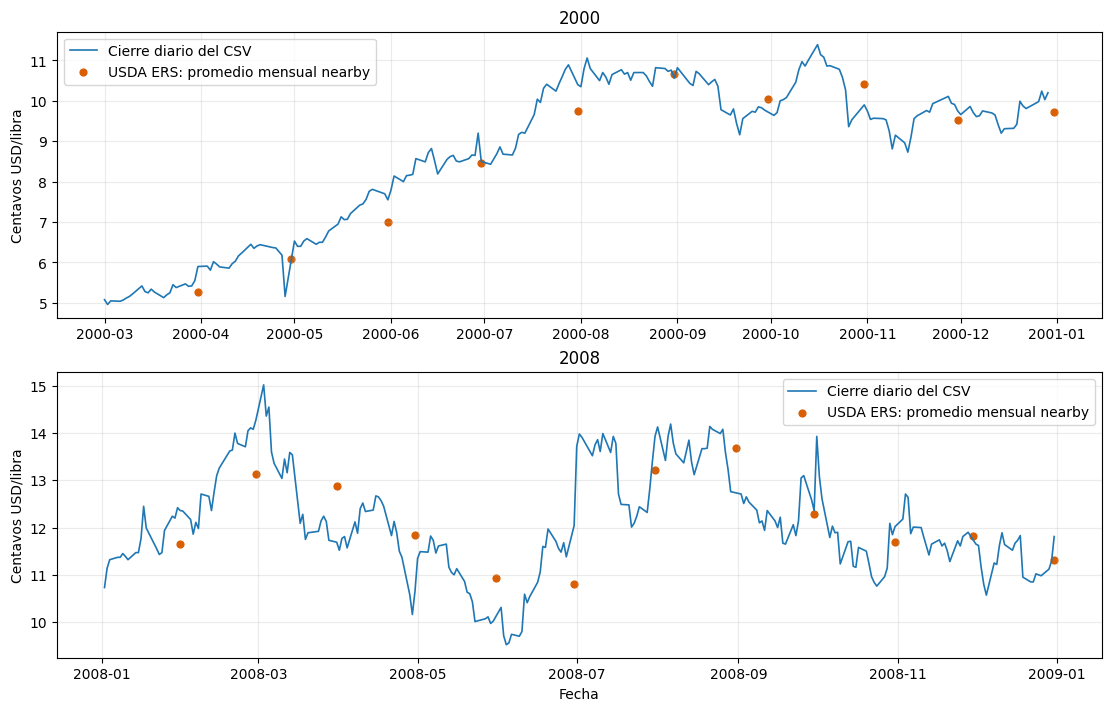

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), constrained_layout=True)
for ax, year in zip(axes, [2000, 2008]):
    diario = crudo.loc[crudo.date.dt.year.eq(year)]
    ref = mensual.loc[mensual.mes.str.startswith(f"{year}-") & mensual.mes_completo_en_archivo]
    ax.plot(diario.date, diario.close, color="#1f77b4", lw=1.2, label="Cierre diario del CSV")
    fechas_mes = pd.PeriodIndex(ref.mes, freq="M").to_timestamp(how="end").normalize()
    ax.scatter(fechas_mes, ref.usda_cercano_mensual, s=24, color="#d95f02", label="USDA ERS: promedio mensual nearby")
    ax.set_title(str(year))
    ax.set_ylabel("Centavos USD/libra")
    ax.grid(alpha=.25)
    ax.legend(loc="best")
axes[-1].set_xlabel("Fecha")
plt.show()

## Evaluación gerencial

El contraste respalda que el archivo sigue el mercado mundial Sugar No. 11 en nivel mensual y contiene movimientos publicados para un mismo vencimiento. Conviene usarlo para análisis históricos descriptivos de mercado con una reserva explícita sobre continuidad, con especial cuidado en retornos alrededor de ventanas de cambio de contrato y filas de calidad marcada. No se debe presentar como historial certificado de un contrato negociable ni usar los saltos señalados como evidencia cuantitativa de riesgo diario sin el identificador del vencimiento.

**Certeza:** moderada para la identidad general del mercado y varios precios cotejados; baja para atribuir retornos diarios de 2000/2008 a un vencimiento específico; insuficiente para certificar el enlace completo. Sin historia contractual, precios simultáneos oficiales y regla de roll histórica de Yahoo no procede corregir la serie ni afirmar que un salto específico fue real o artificial.

**Decisión:** conservar y analizar el original con banderas; mantener las medidas de riesgo como sensibilidad. Para una medición de volatilidad contractual defendible se requieren settlements diarios por vencimiento y una regla explícita de enlace, junto con validación independiente de los límites de roll. No se calcula impacto económico local.